# Training Optimization and Model Selection - Dzifa and Avi

Task #2, part 2. Uses the pipeline from `Model_Setup_InitialTraining.ipynb` for full training runs:

1. GPU environment check
2. Tokenizers for RoBERTa and Legal-BERT (`nlpaueb/legal-bert-base-uncased`)
3. Training with the shared setup (41 labels, `BCEWithLogitsLoss`, Hugging Face `Trainer`)
4. Training and validation loss after every epoch
5. Best epoch and model chosen on the validation set
6. Best checkpoint, test predictions for Task #4, and comparison with the TF-IDF baseline

**Run modes.** `RUN_MODE = "auto"` runs **full** on a GPU and **smoke** on CPU. Smoke mode uses a small subset to check the pipeline; its scores are meaningless.

**Changes from the initial pipeline:** GPU instead of `use_cpu=True`, validation every epoch, best checkpoint kept, fixed seed.

## 0. Google Colab setup
On Colab: clones the repo, installs `requirements.txt`, mounts Google Drive (results are saved there). Does nothing elsewhere.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Break-Through-Tech/Accenture-1H-contract-review-challenge.git"
REPO_BRANCH = "feat/multi-label-training-optimization"   # change to "main" once this is merged
SAVE_TO_DRIVE = True                          # Colab only: keep results/checkpoints on Google Drive

if IN_COLAB:
    repo_dir = "/content/Accenture-1H-contract-review-challenge"
    if not os.path.exists(repo_dir):
        cloned = subprocess.run(["git", "clone", "--depth", "1", "-b", REPO_BRANCH, REPO_URL, repo_dir]).returncode == 0
        if not cloned:   # branch not on GitHub (yet): main has the same data files
            print(f"Branch {REPO_BRANCH} not found, cloning main instead.")
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, repo_dir], check=True)
    os.chdir(f"{repo_dir}/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../requirements.txt"], check=True)
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
print("In Colab:", IN_COLAB, "| working dir:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
In Colab: True | working dir: /content/Accenture-1H-contract-review-challenge/notebooks


## 1. Setup

In [2]:
import gc, json, re, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from datasets import Dataset, DatasetDict, Features, Sequence, Value, load_from_disk, disable_progress_bars
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

transformers.logging.set_verbosity_error()   # hide the expected "newly initialized classifier" warning
disable_progress_bars()                       # keep tokenization output short
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.11.0+cu130 | transformers 4.57.6


All settings. Remove a model from `MODELS_TO_RUN` to train it in a separate session.

In [3]:
RUN_MODE = "auto"      # "auto" (full if a GPU is available, else smoke), "full", or "smoke"
SEED = 42
DATA_DIR = "../data/processed"

MODELS = {   # short tag -> Hugging Face model name
    "roberta": "roberta-base",
    "legal-bert": "nlpaueb/legal-bert-base-uncased",
}
MODELS_TO_RUN = ["roberta", "legal-bert"]
SKIP_FINISHED = False   # don't retrain a model whose summary.json already exists

MAX_LENGTH = 512       # both models' input limit
OVERLAP = 128          # chunk overlap used in Subword_Tokenization_Chunking.ipynb
THRESHOLD = 0.5        # fixed here; per-category thresholds are tuned in Task #3
SELECT_METRIC = "macro_ap"   # validation metric used to choose the best epoch (see section 5)

FULL = dict(num_epochs=15, learning_rate=2e-5, effective_batch_size=16, max_length=MAX_LENGTH,
            warmup_ratio=0.1, weight_decay=0.01, subset=None)
SMOKE = dict(num_epochs=3, learning_rate=5e-5, effective_batch_size=16, max_length=128,
             warmup_ratio=0.1, weight_decay=0.01, subset={"train": 384, "validation": 128, "test": 128})

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"{DATA_DIR} not found. Run this notebook from the notebooks/ folder.")
set_seed(SEED)

## 2. GPU training environment
Checks the device and turns on mixed precision on GPU (bf16 if supported, else fp16). The per-step batch size depends on GPU memory; gradient accumulation keeps the **effective batch size at 16**.

In [4]:
HAS_GPU = torch.cuda.is_available()
MODE = ("full" if HAS_GPU else "smoke") if RUN_MODE == "auto" else RUN_MODE
CFG = dict(FULL if MODE == "full" else SMOKE)

print("Python:", platform.python_version(), "| CPU cores:", os.cpu_count())
if HAS_GPU:
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} | {vram_gb:.1f} GB | CUDA {torch.version.cuda}")
    USE_BF16 = torch.cuda.is_bf16_supported()
    USE_FP16 = not USE_BF16
    per_device = 16 if vram_gb >= 40 else 8 if vram_gb >= 14 else 4
else:
    print("GPU: none found. Training runs on CPU.")
    if IN_COLAB:
        print("  -> On Colab: Runtime > Change runtime type > T4 GPU (or better), then run all again.")
    USE_BF16 = USE_FP16 = False
    per_device = 8
if MODE == "full" and not HAS_GPU:
    print("WARNING: full mode on CPU will take many hours per epoch.")

# Make sure the device can actually run a computation
device = torch.device("cuda" if HAS_GPU else "cpu")
a = torch.randn(1024, 1024, device=device)
assert torch.isfinite(a @ a).all()

CFG["per_device_batch_size"] = min(per_device, CFG["effective_batch_size"])
CFG["grad_accum_steps"] = CFG["effective_batch_size"] // CFG["per_device_batch_size"]
print(f"Device check passed on {device}. Mode: {MODE} | precision: "
      f"{'bf16' if USE_BF16 else 'fp16' if USE_FP16 else 'fp32'} | batch {CFG['per_device_batch_size']} "
      f"x {CFG['grad_accum_steps']} accumulation = {CFG['effective_batch_size']}")

Python: 3.13.15 | CPU cores: 12
GPU: NVIDIA A100-SXM4-40GB | 42.4 GB | CUDA 13.0
Device check passed on cuda. Mode: full | precision: bf16 | batch 16 x 1 accumulation = 16


In [5]:
# results/ is committed, models/ is not. Each run gets its own folder (e.g. 15ep). Smoke runs stay under models/.
RUN_NAME = f"{CFG['num_epochs']}ep"
OUTPUT_ROOT = "/content/drive/MyDrive/Accenture-1H-contract-review-challenge" if (IN_COLAB and SAVE_TO_DRIVE) else ".."
RESULTS_DIR = f"{OUTPUT_ROOT}/results/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke/results"
MODELS_DIR = f"{OUTPUT_ROOT}/models/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
print("Results:", RESULTS_DIR, "\nCheckpoints:", MODELS_DIR)

Results: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/results/training/15ep 
Checkpoints: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep


## 3. Load the chunks and the validation split
Same inputs and 61-contract validation split (`val_titles.json`) as `Transformer_Dataset_Prep.ipynb`. The splits are rebuilt from the text because Legal-BERT needs its own tokenizer; `roberta_dataset/` only has RoBERTa token IDs.

In [6]:
train_df = pd.read_parquet(f"{DATA_DIR}/train_chunks_labeled.parquet")
test_df = pd.read_parquet(f"{DATA_DIR}/test_chunks_labeled.parquet")
with open(f"{DATA_DIR}/categories.json") as f:
    CATEGORIES = json.load(f)
with open(f"{DATA_DIR}/val_titles.json") as f:
    val_titles = set(json.load(f)["val_titles"])
train_titles = set(train_df["title"]) - val_titles

FEATURES = Features({"title": Value("string"), "chunk_id": Value("int64"), "chunk_text": Value("string"),
                     "labels": Sequence(Value("float32"), length=len(CATEGORIES))})

def build_split(df, titles):
    part = df[df["title"].isin(titles)].reset_index(drop=True)
    out = part[["title", "chunk_id", "chunk_text"]].copy()
    out["labels"] = list(part[CATEGORIES].to_numpy(dtype=np.float32))
    return Dataset.from_pandas(out, features=FEATURES, preserve_index=False)

raw = DatasetDict({"train": build_split(train_df, train_titles),
                   "validation": build_split(train_df, val_titles),
                   "test": build_split(test_df, set(test_df["title"]))})

assert len(CATEGORIES) == 41 and len(val_titles) == 61 and len(train_titles) == 347
assert not (val_titles & train_titles) and not (set(train_df["title"]) & set(test_df["title"]))
assert (raw["train"].num_rows, raw["validation"].num_rows, raw["test"].num_rows) == (12112, 2069, 2898)
print({k: v.num_rows for k, v in raw.items()}, "| load checks passed.")

{'train': 12112, 'validation': 2069, 'test': 2898} | load checks passed.


## 4. Tokenizers: RoBERTa and Legal-BERT
- **RoBERTa** (`roberta-base`): cased byte-level BPE. Chunks were cut to 512 RoBERTa tokens.
- **Legal-BERT**: uncased WordPiece pretrained on legal text, so token counts differ.

**Punctuation cleanup for Legal-BERT.** Legal-BERT splits table borders (`--------`) into one token per dash, so some chunks exceed 1,700 tokens. Runs of 3+ identical punctuation marks are shortened to 3 before Legal-BERT tokenization. RoBERTa gets the original text. Apply the same cleanup at prediction time (noted in `training_info.json`).

In [7]:
PUNCT_RUN = re.compile(r"([^\w\s])\1{2,}")
TEXT_CLEANUP = {"roberta": False, "legal-bert": True}

def clean_text(text):
    return PUNCT_RUN.sub(r"\1\1\1", text)

tokenizers = {tag: AutoTokenizer.from_pretrained(MODELS[tag], use_fast=True) for tag in MODELS}

def tokenize_split(ds, tag, max_length):
    tok, cleanup = tokenizers[tag], TEXT_CLEANUP[tag]
    def fn(batch):
        texts = [clean_text(t) for t in batch["chunk_text"]] if cleanup else batch["chunk_text"]
        return tok(texts, max_length=max_length, truncation=True)
    return ds.map(fn, batched=True, remove_columns=["chunk_text"])

for tag, tok in tokenizers.items():
    print(f"{tag:11s} {type(tok).__name__:20s} vocab {tok.vocab_size:,} | lowercase: {bool(getattr(tok, 'do_lower_case', False))} "
          f"| special: {tok.cls_token} ... {tok.sep_token}")

example = "This Agreement shall be governed by the laws of the State of New York."
for tag, tok in tokenizers.items():
    print(f"\n{tag}: {tok.tokenize(example)}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


roberta     RobertaTokenizerFast vocab 50,265 | lowercase: False | special: <s> ... </s>
legal-bert  BertTokenizerFast    vocab 30,522 | lowercase: True | special: [CLS] ... [SEP]

roberta: ['This', 'ĠAgreement', 'Ġshall', 'Ġbe', 'Ġgoverned', 'Ġby', 'Ġthe', 'Ġlaws', 'Ġof', 'Ġthe', 'ĠState', 'Ġof', 'ĠNew', 'ĠYork', '.']

legal-bert: ['this', 'agreement', 'shall', 'be', 'governed', 'by', 'the', 'laws', 'of', 'the', 'state', 'of', 'new', 'york', '.']


### How each tokenizer fits our chunks
Cuts of up to 128 tokens are safe because the next chunk repeats them (overlap). Cuts on a contract's last chunk, or longer than the overlap, lose text.

In [8]:
def length_report(tag):
    tok, rows = tokenizers[tag], []
    for name, ds in raw.items():
        texts = [clean_text(t) for t in ds["chunk_text"]] if TEXT_CLEANUP[tag] else list(ds["chunk_text"])
        lengths = np.array([len(x) for x in tok(texts, verbose=False)["input_ids"]])
        dropped = np.maximum(lengths - MAX_LENGTH, 0)
        chunks = ds.select_columns(["title", "chunk_id"]).to_pandas()
        is_last = (chunks["chunk_id"] == chunks.groupby("title")["chunk_id"].transform("max")).to_numpy()
        rows.append({"model": tag, "split": name, "chunks": len(ds), "median_tokens": int(np.median(lengths)),
                     "max_tokens": int(lengths.max()), "truncated": int((dropped > 0).sum()),
                     "cut_past_overlap": int((dropped > OVERLAP).sum()), "last_chunk_cut": int((dropped[is_last] > 0).sum()),
                     "tokens_lost_%": round(100 * dropped.sum() / lengths.sum(), 2)})
    return rows

lengths_df = pd.DataFrame(length_report("roberta") + length_report("legal-bert"))
lengths_df

,model,split,chunks,median_tokens,max_tokens,truncated,cut_past_overlap,last_chunk_cut,tokens_lost_%
0,roberta,train,12112,512,515,1339,0,0,0.03
1,roberta,validation,2069,512,515,260,0,0,0.03
2,roberta,test,2898,512,515,379,0,0,0.03
3,legal-bert,train,12112,464,937,1016,27,4,0.47
4,legal-bert,validation,2069,470,708,162,3,2,0.28
5,legal-bert,test,2898,470,1228,223,4,1,0.41


In [9]:
# RoBERTa: same as Transformer_Dataset_Prep.ipynb (at most 3 tokens cut, never a last chunk)
rob = lengths_df[lengths_df["model"] == "roberta"]
assert rob["max_tokens"].max() <= MAX_LENGTH + 3 and rob["last_chunk_cut"].sum() == 0
# Legal-BERT: the punctuation cleanup keeps the loss small
lb = lengths_df[lengths_df["model"] == "legal-bert"]
assert lb["tokens_lost_%"].max() < 1.0

# If roberta_dataset/ exists (built by Transformer_Dataset_Prep.ipynb), our RoBERTa tokens must match it exactly
roberta_full = DatasetDict({k: tokenize_split(v, "roberta", MAX_LENGTH) for k, v in raw.items()})
if os.path.exists(f"{DATA_DIR}/roberta_dataset"):
    prepared = load_from_disk(f"{DATA_DIR}/roberta_dataset")
    for k in raw:
        assert prepared[k]["title"] == roberta_full[k]["title"] and prepared[k]["chunk_id"] == roberta_full[k]["chunk_id"]
        assert prepared[k]["input_ids"] == roberta_full[k]["input_ids"] and prepared[k]["labels"] == roberta_full[k]["labels"]
    del prepared
    print("RoBERTa tokens match data/processed/roberta_dataset exactly.")
else:
    print("roberta_dataset/ not found (not in git); skipped the match check.")
del roberta_full
print("Tokenizer checks passed.")

roberta_dataset/ not found (not in git); skipped the match check.
Tokenizer checks passed.


**Result.** RoBERTa: about 11% of chunks lose 1–3 tokens, all within the overlap. Legal-BERT: most chunks are shorter, about 8% still exceed 512, and under 0.5% of tokens are lost after the cleanup.

## 5. Training setup
**Model and loss.** `AutoModelForSequenceClassification` with 41 outputs and `problem_type="multi_label_classification"` (`BCEWithLogitsLoss`). No class weights; those and per-category thresholds are Task #3.

**Best epoch = highest validation macro average precision (AP).** AP doesn't depend on a threshold, and macro averaging weights rare categories equally. Validation loss and F1 at 0.5 are reported too. Categories with no positives in a split are excluded (as in the baseline).

In [10]:
def multilabel_scores(y_true, probs, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    has_pos = y_true.sum(axis=0) > 0
    yt, pr = y_true[:, has_pos], probs[:, has_pos]
    yp = (pr >= threshold).astype(int)
    scores = {"macro_ap": average_precision_score(yt, pr, average="macro"),
              "micro_ap": average_precision_score(yt, pr, average="micro")}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0)
        scores.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    scores["categories_scored"] = int(has_pos.sum())
    return scores

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return multilabel_scores(labels, sigmoid(logits))

# Quick check on made-up data: perfect predictions score 1, and a category with no positives is skipped
y = np.array([[1, 0, 0], [0, 1, 0], [1, 1, 0]])
s = multilabel_scores(y, y.astype(float))
assert s["macro_ap"] == 1 and s["micro_f1"] == 1 and s["categories_scored"] == 2
print("Metric checks passed.")

Metric checks passed.


In [11]:
def prepare_splits(tag):
    # Tokenized train / validation / test for one model. Smoke mode uses a fixed random subset.
    splits = {}
    for name, ds in raw.items():
        if CFG["subset"]:
            ds = ds.shuffle(seed=SEED).select(range(CFG["subset"][name]))
        splits[name] = tokenize_split(ds, tag, CFG["max_length"])
    return splits

def training_args(out_dir):
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=CFG["num_epochs"],
        learning_rate=CFG["learning_rate"],
        per_device_train_batch_size=CFG["per_device_batch_size"],
        per_device_eval_batch_size=CFG["per_device_batch_size"] * 2,
        gradient_accumulation_steps=CFG["grad_accum_steps"],
        warmup_ratio=CFG["warmup_ratio"],
        weight_decay=CFG["weight_decay"],
        eval_strategy="epoch",            # validation loss + scores after every epoch
        logging_strategy="epoch",         # training loss averaged over each epoch
        save_strategy="epoch",
        save_total_limit=1,               # keeps the best checkpoint (and the latest one)
        save_only_model=True,             # no optimizer state: ~0.5 GB per checkpoint instead of ~1.5 GB
        load_best_model_at_end=True,
        metric_for_best_model=SELECT_METRIC,
        greater_is_better=True,
        bf16=USE_BF16, fp16=USE_FP16,
        dataloader_num_workers=2 if HAS_GPU else 0,
        dataloader_pin_memory=HAS_GPU,
        seed=SEED, data_seed=SEED,
        report_to="none",
        disable_tqdm=not HAS_GPU,         # keep the saved CPU smoke run readable
    )

## 6. Train
For each model: train for `num_epochs` with validation after each epoch, reload the best epoch, then save:
- checkpoint and tokenizer to `models/training/<run>/<model>/best/`
- history, test predictions and summary to `results/training/<run>/<model>/`

`<run>` is the epoch count (e.g. `15ep`), so new runs don't overwrite old ones. With `SKIP_FINISHED`, finished models are skipped.

In [12]:
def epoch_history(log_history):
    train = {round(h["epoch"]): h["loss"] for h in log_history if "loss" in h and "eval_loss" not in h}
    rows = []
    for h in log_history:
        if "eval_loss" in h:
            e = round(h["epoch"])
            rows.append({"epoch": e, "train_loss": train.get(e), "val_loss": h["eval_loss"],
                         **{k[5:]: v for k, v in h.items() if k.startswith("eval_") and k[5:] in
                            ["macro_ap", "micro_ap", "micro_f1", "macro_f1", "micro_precision", "micro_recall"]}})
    return pd.DataFrame(rows)

def run_experiment(tag):
    res_dir, model_dir = f"{RESULTS_DIR}/{tag}", f"{MODELS_DIR}/{tag}"
    if SKIP_FINISHED and os.path.exists(f"{res_dir}/summary.json"):
        print(f"[{tag}] already finished, skipping (set SKIP_FINISHED = False to retrain)")
        return
    os.makedirs(res_dir, exist_ok=True)
    set_seed(SEED)
    splits = prepare_splits(tag)
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[tag], num_labels=len(CATEGORIES), problem_type="multi_label_classification",
        id2label=dict(enumerate(CATEGORIES)), label2id={c: i for i, c in enumerate(CATEGORIES)})
    trainer = Trainer(model=model, args=training_args(f"{model_dir}/checkpoints"),
                      train_dataset=splits["train"].select_columns(cols),
                      eval_dataset=splits["validation"].select_columns(cols),
                      data_collator=DataCollatorWithPadding(tokenizers[tag]),
                      compute_metrics=compute_metrics)

    print(f"[{tag}] training {MODELS[tag]} on {splits['train'].num_rows:,} chunks for {CFG['num_epochs']} epochs ...")
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    history = epoch_history(trainer.state.log_history)
    best = history.loc[history[SELECT_METRIC].idxmax()]
    best_epoch = int(best["epoch"])
    history.to_csv(f"{res_dir}/epoch_history.csv", index=False)

    # Best checkpoint (load_best_model_at_end already put it back into trainer.model)
    best_dir = f"{model_dir}/best"
    trainer.save_model(best_dir)
    tokenizers[tag].save_pretrained(best_dir)

    # Per-category validation scores of the best epoch (input for Task #3)
    val_probs = sigmoid(trainer.predict(splits["validation"].select_columns(cols)).predictions)
    y_val = np.array(splits["validation"]["labels"])
    pd.DataFrame({"val_ap": [average_precision_score(y_val[:, j], val_probs[:, j]) if y_val[:, j].any() else np.nan
                             for j in range(len(CATEGORIES))],
                  "val_positives": y_val.sum(0).astype(int)}, index=CATEGORIES).to_csv(f"{res_dir}/val_per_category.csv")

    # Test predictions for Task #4: one row per chunk, one probability per category
    test_probs = sigmoid(trainer.predict(splits["test"].select_columns(cols)).predictions)
    preds = pd.DataFrame(test_probs, columns=CATEGORIES)
    preds.insert(0, "chunk_id", splits["test"]["chunk_id"])
    preds.insert(0, "title", splits["test"]["title"])
    preds.to_parquet(f"{res_dir}/test_predictions.parquet", index=False)
    test_scores = multilabel_scores(np.array(splits["test"]["labels"]), test_probs)

    summary = {"model": MODELS[tag], "tag": tag, "mode": MODE, "best_epoch": best_epoch,
               "select_metric": SELECT_METRIC, "best_val": {k: float(v) for k, v in best.items() if k != "epoch"},
               "test_at_best_epoch": {k: float(v) for k, v in test_scores.items()},
               "train_minutes": round(minutes, 1),
               "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
               "config": CFG, "text_cleanup": TEXT_CLEANUP[tag],
               "train_chunks": splits["train"].num_rows, "checkpoint": best_dir}
    with open(f"{best_dir}/training_info.json", "w") as f:
        json.dump({**summary, "categories": CATEGORIES,
                   "note": "apply clean_text() (runs of 3+ identical punctuation -> 3) before tokenizing" if TEXT_CLEANUP[tag] else ""}, f, indent=1)
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)

    print(f"[{tag}] done in {minutes:.1f} min. Best epoch: {best_epoch} (val {SELECT_METRIC} {best[SELECT_METRIC]:.3f})")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

for tag in MODELS_TO_RUN:
    run_experiment(tag)

[roberta] training roberta-base on 12,112 chunks for 15 epochs ...


Epoch,Training Loss,Validation Loss,Macro Ap,Micro Ap,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Categories Scored
1,0.262300,0.098927,0.033345,0.041384,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,41
2,0.085300,0.080877,0.133659,0.240650,0.866667,0.091927,0.166223,0.087459,0.054475,0.059016,41
3,0.064300,0.063048,0.344857,0.525175,0.857621,0.301709,0.446382,0.241014,0.159221,0.180425,41
4,0.049500,0.050781,0.404282,0.612258,0.836983,0.405421,0.546249,0.329526,0.239732,0.261792,41
5,0.040600,0.047195,0.455347,0.650948,0.819106,0.474956,0.601268,0.442035,0.300065,0.325465,41
6,0.034500,0.046199,0.464780,0.658043,0.752818,0.550972,0.636271,0.483206,0.364153,0.388936,41
7,0.029900,0.044151,0.494999,0.683969,0.736201,0.605186,0.664295,0.497200,0.409177,0.425018,41
8,0.026300,0.042317,0.505374,0.695330,0.781673,0.578079,0.664634,0.536158,0.391622,0.426188,41
9,0.023200,0.040931,0.516538,0.701519,0.769406,0.595757,0.671538,0.558097,0.411527,0.447021,41
10,0.020600,0.041261,0.523612,0.704972,0.775373,0.612257,0.684228,0.576621,0.429136,0.468490,41


[roberta] done in 13.5 min. Best epoch: 15 (val macro_ap 0.542)
[legal-bert] training nlpaueb/legal-bert-base-uncased on 12,112 chunks for 15 epochs ...


Epoch,Training Loss,Validation Loss,Macro Ap,Micro Ap,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Categories Scored
1,0.298300,0.103900,0.030185,0.038848,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,41
2,0.087900,0.080529,0.189740,0.323321,1.000000,0.011786,0.023296,0.048780,0.005892,0.009855,41
3,0.064300,0.060093,0.372755,0.563243,0.927686,0.264585,0.411738,0.247817,0.135037,0.161420,41
4,0.048800,0.050608,0.453625,0.625397,0.840708,0.391868,0.534566,0.376447,0.224644,0.249843,41
5,0.039900,0.046886,0.491377,0.677494,0.804408,0.516205,0.628859,0.491042,0.337561,0.371693,41
6,0.033300,0.043257,0.521902,0.695191,0.808584,0.555097,0.658281,0.557972,0.368490,0.415024,41
7,0.028300,0.041533,0.544307,0.713737,0.798144,0.608132,0.690301,0.576553,0.425060,0.468929,41
8,0.024300,0.040238,0.562169,0.721088,0.789116,0.615203,0.691391,0.572834,0.439974,0.483475,41
9,0.021300,0.039113,0.572846,0.727510,0.779230,0.632292,0.698113,0.606721,0.455825,0.495542,41
10,0.018900,0.039281,0.584884,0.731821,0.795572,0.635239,0.706422,0.624958,0.460410,0.509696,41


[legal-bert] done in 13.5 min. Best epoch: 15 (val macro_ap 0.593)


## 7. Compare epochs and models
### Loss per epoch

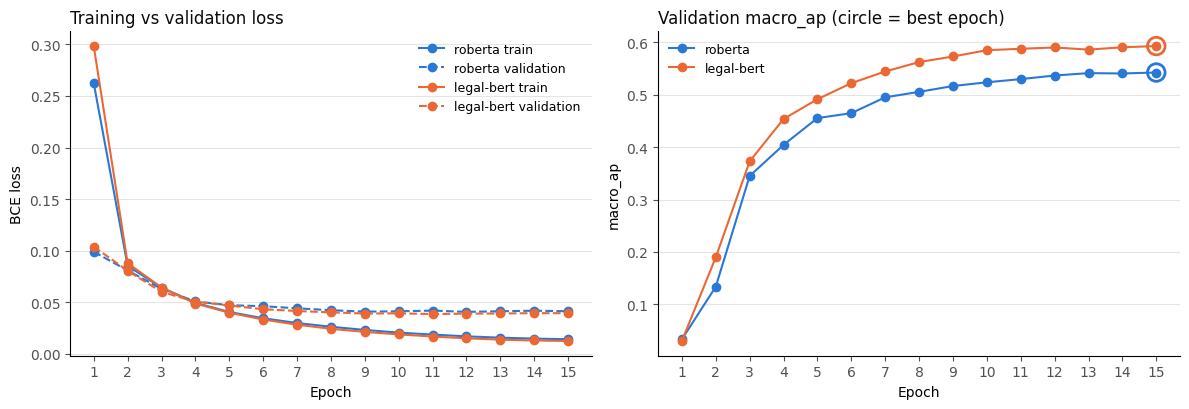

In [13]:
summaries, histories = {}, {}
for tag in MODELS:
    if os.path.exists(f"{RESULTS_DIR}/{tag}/summary.json"):
        with open(f"{RESULTS_DIR}/{tag}/summary.json") as f:
            summaries[tag] = json.load(f)
        histories[tag] = pd.read_csv(f"{RESULTS_DIR}/{tag}/epoch_history.csv")
assert summaries, "No finished runs found. Run section 6 first."

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
COLORS = {"roberta": "#2a78d6", "legal-bert": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for tag, h in histories.items():
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", color=COLORS[tag], label=f"{tag} train")
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", linestyle="--", color=COLORS[tag], label=f"{tag} validation")
    axes[1].plot(h["epoch"], h[SELECT_METRIC], marker="o", color=COLORS[tag], label=tag)
    b = summaries[tag]["best_epoch"]
    axes[1].scatter([b], [h.loc[h["epoch"] == b, SELECT_METRIC].iloc[0]], s=160, facecolors="none",
                    edgecolors=COLORS[tag], linewidths=2, zorder=3)
axes[0].set_title("Training vs validation loss", loc="left", color=INK)
axes[0].set_ylabel("BCE loss")
axes[1].set_title(f"Validation {SELECT_METRIC} (circle = best epoch)", loc="left", color=INK)
axes[1].set_ylabel(SELECT_METRIC)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(sorted({e for h in histories.values() for e in h["epoch"]}))
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
if MODE == "smoke":
    fig.suptitle("SMOKE RUN (CPU, tiny subset): checks the pipeline only, the numbers are not meaningful", color="#b3261e", fontsize=10)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Validation scores per epoch

In [14]:
table = pd.concat({tag: h.set_index("epoch") for tag, h in histories.items()}, names=["model", "epoch"])
table.round(4)

train_loss  val_loss  macro_ap  micro_ap  micro_precision  \
model      epoch                                                              
roberta    1          0.2623    0.0989    0.0333    0.0414           0.0000   
           2          0.0853    0.0809    0.1337    0.2407           0.8667   
           3          0.0643    0.0630    0.3449    0.5252           0.8576   
           4          0.0495    0.0508    0.4043    0.6123           0.8370   
           5          0.0406    0.0472    0.4553    0.6509           0.8191   
           6          0.0345    0.0462    0.4648    0.6580           0.7528   
           7          0.0299    0.0442    0.4950    0.6840           0.7362   
           8          0.0263    0.0423    0.5054    0.6953           0.7817   
           9          0.0232    0.0409    0.5165    0.7015           0.7694   
           10         0.0206    0.0413    0.5236    0.7050           0.7754   
           11         0.0187    0.0419    0.5297    0.7098           0.7205   
           12         0.0170    0.0407    0.5366    0.7133           0.7615   
           13         0.0157    0.0413    0.5411    0.7090           0.7416   
           14         0.0148    0.0418    0.5405    0.7136           0.7323   
           15         0.0142    0.0413    0.5423    0.7154           0.7510   
legal-bert 1          0.2983    0.1039    0.0302    0.0388           0.0000   
           2          0.0879    0.0805    0.1897    0.3233           1.0000   
           3          0.0643    0.0601    0.3728    0.5632           0.9277   
           4          0.0488    0.0506    0.4536    0.6254           0.8407   
           5          0.0399    0.0469    0.4914    0.6775           0.8044   
           6          0.0333    0.0433    0.5219    0.6952           0.8086   
           7          0.0283    0.0415    0.5443    0.7137           0.7981   
           8          0.0243    0.0402    0.5622    0.7211           0.7891   
           9          0.0213    0.0391    0.5728    0.7275           0.7792   
           10         0.0189    0.0393    0.5849    0.7318           0.7956   
           11         0.0168    0.0386    0.5876    0.7364           0.7857   
           12         0.0151    0.0390    0.5901    0.7347           0.7767   
           13         0.0138    0.0391    0.5860    0.7343           0.7829   
           14         0.0130    0.0394    0.5904    0.7329           0.7786   
           15         0.0125    0.0394    0.5927    0.7347           0.7846   

                  micro_recall  micro_f1  macro_f1  
model      epoch                                    
roberta    1            0.0000    0.0000    0.0000  
           2            0.0919    0.1662    0.0590  
           3            0.3017    0.4464    0.1804  
           4            0.4054    0.5462    0.2618  
           5            0.4750    0.6013    0.3255  
           6            0.5510    0.6363    0.3889  
           7            0.6052    0.6643    0.4250  
           8            0.5781    0.6646    0.4262  
           9            0.5958    0.6715    0.4470  
           10           0.6123    0.6842    0.4685  
           11           0.6470    0.6818    0.4868  
           12           0.6323    0.6909    0.4937  
           13           0.6494    0.6924    0.5022  
           14           0.6594    0.6940    0.5126  
           15           0.6506    0.6972    0.5122  
legal-bert 1            0.0000    0.0000    0.0000  
           2            0.0118    0.0233    0.0099  
           3            0.2646    0.4117    0.1614  
           4            0.3919    0.5346    0.2498  
           5            0.5162    0.6289    0.3717  
           6            0.5551    0.6583    0.4150  
           7            0.6081    0.6903    0.4689  
           8            0.6152    0.6914    0.4835  
           9            0.6323    0.6981    0.4955  
           10           0.6352    0.7064    0.5097  
           11           0.6547    0.7142    0.5337  
     

### Best model and epoch
Chosen on validation only. Test is scored once for comparison with TF-IDF (`TF-IDF_Baseline.ipynb`: micro F1 0.591, macro F1 0.517 at 0.5).

In [15]:
TFIDF_TEST = {"micro_f1": 0.591, "macro_f1": 0.517}   # from TF-IDF_Baseline.ipynb

best_tag = max(summaries, key=lambda t: summaries[t]["best_val"][SELECT_METRIC])
rows = []
for tag, s in summaries.items():
    rows.append({"model": tag, "best_epoch": s["best_epoch"], f"val_{SELECT_METRIC}": s["best_val"][SELECT_METRIC],
                 "val_micro_f1": s["best_val"]["micro_f1"], "val_macro_f1": s["best_val"]["macro_f1"],
                 "test_micro_f1": s["test_at_best_epoch"]["micro_f1"], "test_macro_f1": s["test_at_best_epoch"]["macro_f1"],
                 "train_minutes": s["train_minutes"], "chosen": tag == best_tag})
rows.append({"model": "tf-idf baseline", "test_micro_f1": TFIDF_TEST["micro_f1"], "test_macro_f1": TFIDF_TEST["macro_f1"]})
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(f"{RESULTS_DIR}/model_comparison.csv")

print(f"Chosen: {best_tag} ({summaries[best_tag]['model']}), epoch {summaries[best_tag]['best_epoch']}, "
      f"checkpoint: {summaries[best_tag]['checkpoint']}")
if MODE == "smoke":
    print("SMOKE RUN: the comparison only shows the pipeline works. Re-run on a GPU for real results.")
comparison.round(3)

Chosen: legal-bert (nlpaueb/legal-bert-base-uncased), epoch 15, checkpoint: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep/legal-bert/best


,best_epoch,val_macro_ap,val_micro_f1,val_macro_f1,test_micro_f1,test_macro_f1,train_minutes,chosen
model,,,,,,,,
roberta,15.0,0.542,0.697,0.512,0.692,0.524,13.5,False
legal-bert,15.0,0.593,0.714,0.532,0.703,0.569,13.5,True
tf-idf baseline,NaN,NaN,NaN,NaN,0.591,0.517,NaN,NaN


### Weakest categories on validation (chosen model)
Focus areas for Task #3.

In [16]:
per_cat = pd.read_csv(f"{RESULTS_DIR}/{best_tag}/val_per_category.csv", index_col=0)
per_cat.sort_values("val_ap").head(10).round(3)

,val_ap,val_positives
Most Favored Nation,0.005,4
Affiliate License-Licensor,0.008,3
Price Restrictions,0.010,8
Unlimited/All-You-Can-Eat-License,0.048,5
Third Party Beneficiary,0.127,9
Competitive Restriction Exception,0.144,14
Volume Restriction,0.181,19
Source Code Escrow,0.275,9
No-Solicit Of Customers,0.343,8
Affiliate License-Licensee,0.362,25


## 8. Files saved
| File | In git | Contents |
|---|---|---|
| `results/training/<run>/<model>/epoch_history.csv` | Yes | Loss and validation scores per epoch |
| `results/training/<run>/<model>/summary.json` | Yes | Best epoch, validation and test scores, settings |
| `results/training/<run>/<model>/val_per_category.csv` | Yes | Validation AP per category (for Task #3) |
| `results/training/<run>/<model>/test_predictions.parquet` | Yes | `title`, `chunk_id`, 41 probabilities per test chunk (for Task #4) |
| `results/training/<run>/model_comparison.csv`, `loss_curves.png` | Yes | Comparison (marks the chosen model) and loss plot |
| `models/training/<run>/<model>/best/` | No (~0.5 GB) | Best checkpoint, tokenizer, `training_info.json` |

On Colab these are under `MyDrive/Accenture-1H-contract-review-challenge/`. Smoke runs go to `models/training_smoke/`. The next cell downloads the results as a zip.

In [17]:
if IN_COLAB and MODE == "full":
    archive = shutil.make_archive("/content/results_training", "zip", RESULTS_DIR)
    from google.colab import files
    files.download(archive)
    print("Downloading", archive, f"- unzip it into results/training/{RUN_NAME}/ in the repo and commit.")
else:
    print("Nothing to download here." if not IN_COLAB else "Smoke run: nothing worth downloading.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Results and limitations
**Results (A100, 15 epochs).** Legal-BERT is chosen: validation macro AP 0.593 vs 0.542 for RoBERTa. At threshold 0.5 it reaches test micro F1 **0.703** and macro F1 **0.569**, vs 0.591 / 0.517 for TF-IDF. Validation loss bottoms out around epoch 11 and AP barely changes after, so 11–15 epochs is enough. Files are in `results/training/15ep/`.

**Limitations**
- Legal-BERT still loses under 0.5% of tokens to truncation; re-chunking with its tokenizer would fix this.
- Fixed 0.5 threshold and no class weights, so rare categories score low (Task #3).
- One seed and one learning rate: differences of about ±0.01 may be noise.
- TF-IDF trained on all 408 contracts; the transformers on 347 (61 held out for validation).
- Price Restrictions has no test positives, so it's excluded from test averages.